# Bài 8 · Attention và Transformer từ đầu

**Thời lượng gợi ý:** 210 phút · **Cần:** Bài 7 · **Chạy được trên CPU** (vài phút)

## Mục tiêu

1. Hiểu **attention** như một phép *tra cứu mềm* (Query–Key–Value) và tự cài đặt bằng NumPy.
2. Giải thích **vì sao chia cho √d**, vai trò của **mặt nạ** (padding, nhân quả) và của **mã hóa vị trí**.
3. Cài đặt **multi-head self-attention** và một **khối Transformer** bằng PyTorch; huấn luyện bộ phân loại.
4. Đối chiếu trực tiếp với Bài 7: attention gỡ **nút thắt** của seq2seq như thế nào.
5. Xây một **mini-GPT** (mô hình ngôn ngữ nhân quả) để thấy "sinh văn bản" chỉ là dự đoán token kế tiếp — cầu nối sang LLM.

> Bài này dài và là **trái tim của cả khóa**: PhoBERT (Bài 10), mô hình embedding (Bài 12) và LLM (Bài 13) đều là Transformer. Đừng vội; hãy chạy từng ô, đổi thử tham số và đọc kết quả.

In [1]:
import sys, pathlib

ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import math
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from nlpvi import LABELS, load_splits, load_hard, normalize, segment, split_sentences, set_seed
from nlpvi.textnn import build_vocab, TextDS, evaluate, fit, tach_tu

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
set_seed(42)
device = "cpu"
train, valid, test = load_splits()
hard = load_hard()
CLASSES = sorted(LABELS); c2i = {c: i for i, c in enumerate(CLASSES)}
itos, stoi = build_vocab(train["text"])
ds_tr, ds_va, ds_hard = (TextDS(d, stoi, c2i) for d in (train, valid, hard))
V = len(itos)

## 1. Từ nút thắt đến attention

Ở Bài 7, decoder chỉ được nhìn **một** vector tóm tắt toàn câu nguồn. Ý tưởng của attention: *đừng nén — hãy giữ lại tất cả trạng thái của câu nguồn và để decoder tự chọn chỗ cần nhìn ở mỗi bước*.

Hình dung như tra từ điển "mềm":

- **Query** (câu hỏi): "tôi đang cần thông tin gì?"
- **Key** (nhãn của từng mục): "mục này nói về cái gì?"
- **Value** (nội dung của mục).

Ta so Query với mọi Key (tích vô hướng) → được điểm giống nhau → **softmax** thành trọng số → lấy **trung bình có trọng số của các Value**:

$$\text{Attention}(Q,K,V)=\text{softmax}\!\Big(\frac{QK^\top}{\sqrt{d_k}}\Big)V$$

## 2. Scaled dot-product attention bằng NumPy

In [2]:
def softmax(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

def attention(Q, K, V, mask=None):
    d = Q.shape[-1]
    scores = Q @ K.swapaxes(-1, -2) / np.sqrt(d)
    if mask is not None:
        scores = np.where(mask, scores, -1e9)
    w = softmax(scores)
    return w @ V, w

# 4 "từ", mỗi từ có vector 3 chiều (dùng chung Q=K=V để dễ quan sát)
tu = ["giao", "hàng", "rất", "chậm"]
X = np.array([[1.0, 0.1, 0.0],
              [0.9, 0.2, 0.1],
              [0.0, 1.0, 0.1],
              [0.1, 0.9, 1.0]])
out, w = attention(X, X, X)
print(pd.DataFrame(w, index=[f"hỏi từ '{t}'" for t in tu], columns=[f"nhìn '{t}'" for t in tu]).round(2).to_string())
print("\nMỗi hàng cộng bằng 1:", w.sum(axis=1).round(3))

               nhìn 'giao'  nhìn 'hàng'  nhìn 'rất'  nhìn 'chậm'
hỏi từ 'giao'         0.32         0.30        0.19         0.20
hỏi từ 'hàng'         0.30         0.29        0.20         0.22
hỏi từ 'rất'          0.18         0.20        0.31         0.31
hỏi từ 'chậm'         0.16         0.18        0.25         0.41

Mỗi hàng cộng bằng 1: [1. 1. 1. 1.]


Mỗi hàng là một phân phối: từ ở hàng đó *chú ý* tới từng từ khác bao nhiêu. "giao" và "hàng" có vector gần nhau nên chú ý lẫn nhau nhiều. Đầu ra mới của mỗi từ là trung bình có trọng số các vector giá trị — tức **biểu diễn của một từ giờ chứa thông tin ngữ cảnh**.

### Vì sao chia cho √d?

Nếu các thành phần của Q và K có phương sai 1, tích vô hướng của hai vector d chiều có phương sai **d**. Giá trị lớn đẩy softmax vào vùng bão hòa (một phần tử ≈ 1, còn lại ≈ 0), nơi gradient gần như bằng 0. Chia cho √d đưa phương sai về 1.

In [3]:
rng = np.random.default_rng(0)
hang = []
for d in [4, 16, 64, 256, 1024]:
    q = rng.normal(size=(2000, d)); k = rng.normal(size=(2000, d))
    s = (q * k).sum(1)
    hang.append({"d": d, "std của q·k": round(s.std(), 2), "std của q·k/√d": round((s / np.sqrt(d)).std(), 2)})
print(pd.DataFrame(hang).to_string(index=False))

z = rng.normal(size=(8,)) * 32                  # độ lớn tương ứng d≈1024 khi không chia
print("\nSoftmax khi KHÔNG chia (điểm lớn):", softmax(z).round(2))
print("Softmax khi chia √d              :", softmax(z / np.sqrt(1024)).round(2))

   d  std của q·k  std của q·k/√d
   4         2.04            1.02
  16         3.95            0.99
  64         8.10            1.01
 256        15.80            0.99
1024        31.78            0.99



Softmax khi KHÔNG chia (điểm lớn): [0. 1. 0. 0. 0. 0. 0. 0.]
Softmax khi chia √d              : [0.04 0.49 0.1  0.02 0.05 0.05 0.12 0.14]


## 3. Mặt nạ (mask)

Hai loại mặt nạ cần nhớ:

- **Mặt nạ đệm (padding mask)**: ô `<pad>` không mang thông tin, không được ai "nhìn" vào.
- **Mặt nạ nhân quả (causal mask)**: khi sinh văn bản, vị trí *t* **chỉ được nhìn các vị trí ≤ t** (không "nhìn trộm" tương lai).

Cách cài: đặt điểm của ô bị cấm bằng $-\infty$ trước softmax → trọng số bằng 0.

In [4]:
L = 5
causal = np.tril(np.ones((L, L), dtype=bool))
Xs = rng.normal(size=(L, 8))
_, w_c = attention(Xs, Xs, Xs, mask=causal)
print("Trọng số attention với mặt nạ nhân quả (hàng = vị trí hỏi):")
print(pd.DataFrame(w_c).round(2).to_string())

Trọng số attention với mặt nạ nhân quả (hàng = vị trí hỏi):
      0     1     2     3     4
0  1.00  0.00  0.00  0.00  0.00
1  0.00  1.00  0.00  0.00  0.00
2  0.12  0.20  0.68  0.00  0.00
3  0.03  0.38  0.06  0.53  0.00
4  0.14  0.12  0.17  0.15  0.42


Ma trận **tam giác dưới**: từ thứ 0 chỉ nhìn chính nó, từ thứ 4 nhìn cả 5 từ. Mô hình sinh văn bản (GPT, Qwen, Claude...) đều dùng mặt nạ này.

## 4. Attention không biết thứ tự → cần mã hóa vị trí

Self-attention coi câu là **một tập** từ: nếu xáo thứ tự đầu vào, đầu ra chỉ bị xáo theo (tính chất *hoán vị tương đương*). Tức "chó cắn người" và "người cắn chó" cho cùng tập biểu diễn. Ta kiểm chứng bằng số:

In [5]:
Xp = rng.normal(size=(6, 8))
perm = rng.permutation(6)
o1, _ = attention(Xp, Xp, Xp)
o2, _ = attention(Xp[perm], Xp[perm], Xp[perm])
print("Đầu ra khi xáo đầu vào == xáo đầu ra ban đầu ?", np.allclose(o2, o1[perm]))

Đầu ra khi xáo đầu vào == xáo đầu ra ban đầu ? True


Để mô hình biết thứ tự, ta **cộng thêm vector vị trí** vào embedding từ. Bản gốc (Vaswani và cộng sự, 2017) dùng hàm sin/cos nhiều tần số:

$$\text{PE}(pos,2i)=\sin\!\big(pos/10000^{2i/d}\big),\qquad \text{PE}(pos,2i+1)=\cos\!\big(pos/10000^{2i/d}\big)$$

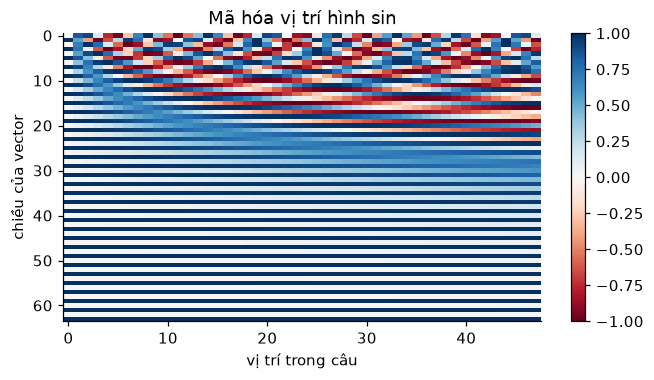

In [6]:
def sinusoidal(L, d):
    pos = np.arange(L)[:, None]
    i = np.arange(0, d, 2)[None, :]
    ang = pos / (10000 ** (i / d))
    pe = np.zeros((L, d))
    pe[:, 0::2], pe[:, 1::2] = np.sin(ang), np.cos(ang)
    return pe

pe = sinusoidal(48, 64)
plt.figure(figsize=(7, 3.4))
plt.imshow(pe.T, aspect="auto", cmap="RdBu", vmin=-1, vmax=1)
plt.xlabel("vị trí trong câu"); plt.ylabel("chiều của vector"); plt.title("Mã hóa vị trí hình sin"); plt.colorbar()
plt.show()

Chiều thấp dao động nhanh (phân biệt vị trí kề nhau), chiều cao dao động chậm (phân biệt vị trí xa). Mỗi vị trí có một "vân tay" riêng. Nhiều mô hình hiện đại dùng cách khác (vị trí học được, RoPE, ALiBi), nhưng ý tưởng — *đưa thông tin vị trí vào* — là chung.

## 5. Multi-head attention và khối Transformer bằng PyTorch

**Nhiều đầu (heads)**: thay vì một phép attention, chia chiều `d` thành `h` phần và chạy `h` phép attention song song, mỗi đầu có thể chuyên về một kiểu quan hệ (cú pháp, phủ định, vị trí...). Rồi nối các đầu lại và chiếu qua một ma trận đầu ra.

**Khối Transformer** = (self-attention + kết nối tắt + chuẩn hóa) rồi (mạng truyền thẳng theo từng vị trí + kết nối tắt + chuẩn hóa). Ta dùng biến thể *Pre-LN* (chuẩn hóa trước mỗi nhánh), ổn định hơn khi huấn luyện.

In [7]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d, h, p=0.1):
        super().__init__()
        assert d % h == 0
        self.h, self.dk = h, d // h
        self.qkv = nn.Linear(d, 3 * d)
        self.o = nn.Linear(d, d)
        self.drop = nn.Dropout(p)

    def forward(self, x, mask=None):                 # x: (B, L, d); mask: True = được nhìn
        B, L, d = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q, k, v = (t.view(B, L, self.h, self.dk).transpose(1, 2) for t in (q, k, v))     # (B, h, L, dk)
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.dk)                            # (B, h, L, L)
        if mask is not None:
            scores = scores.masked_fill(~mask, -1e9)
        w = scores.softmax(-1)
        out = (self.drop(w) @ v).transpose(1, 2).reshape(B, L, d)
        return self.o(out), w

class Block(nn.Module):
    def __init__(self, d, h, p=0.1):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = MultiHeadAttention(d, h, p)
        self.ffn = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
        self.drop = nn.Dropout(p)

    def forward(self, x, mask=None):
        a, w = self.attn(self.ln1(x), mask)
        x = x + self.drop(a)                              # kết nối tắt (residual)
        x = x + self.drop(self.ffn(self.ln2(x)))
        return x, w

# --- Hai kiểm tra tính đúng đắn ---
set_seed(0)
blk = Block(32, 4).eval()
x = torch.randn(1, 6, 32)
causal_t = torch.tril(torch.ones(6, 6, dtype=torch.bool))[None, None]

y1, _ = blk(x, causal_t)
x2 = x.clone(); x2[:, 4:] = torch.randn(1, 2, 32)          # đổi các token TƯƠNG LAI (vị trí 4, 5)
y2, _ = blk(x2, causal_t)
print("(1) Mặt nạ nhân quả: đổi tương lai thì đầu ra các vị trí 0..3 không đổi ?", torch.allclose(y1[:, :4], y2[:, :4], atol=1e-6))

perm = torch.randperm(6)
y3, _ = blk(x[:, perm])
y4, _ = blk(x)
print("(2) Không mặt nạ, không vị trí: xáo đầu vào = xáo đầu ra ?", torch.allclose(y3, y4[:, perm], atol=1e-5))

(1) Mặt nạ nhân quả: đổi tương lai thì đầu ra các vị trí 0..3 không đổi ? True
(2) Không mặt nạ, không vị trí: xáo đầu vào = xáo đầu ra ? True


## 6. Bộ phân loại Transformer và so sánh với Bài 6–7

Ta xếp 2 khối Transformer, cộng mã hóa vị trí hình sin, gộp trung bình các vị trí (bỏ qua ô đệm) rồi phân loại. Mô hình này huấn luyện **từ đầu** trên 1.262 mẫu.

In [8]:
class TransformerPhanLoai(nn.Module):
    def __init__(self, V, d=64, h=4, n_layers=2, max_len=48, n_cls=3, p=0.1):
        super().__init__()
        self.d = d
        self.emb = nn.Embedding(V, d, padding_idx=0)
        self.register_buffer("pe", torch.tensor(sinusoidal(max_len, d), dtype=torch.float))
        self.blocks = nn.ModuleList([Block(d, h, p) for _ in range(n_layers)])
        self.ln = nn.LayerNorm(d)
        self.drop = nn.Dropout(0.3)
        self.fc = nn.Linear(d, n_cls)

    def forward(self, x, return_attn=False):
        pad = x != 0
        mask = pad[:, None, None, :]                       # không nhìn vào ô đệm
        z = self.emb(x) * math.sqrt(self.d) + self.pe[: x.size(1)]
        attn = []
        for b in self.blocks:
            z, w = b(z, mask)
            attn.append(w)
        z = self.ln(z)
        m = pad.unsqueeze(-1).float()
        out = self.fc(self.drop((z * m).sum(1) / m.sum(1).clamp(min=1)))
        return (out, attn) if return_attn else out

set_seed(0)
t0 = time.time()
tf_model = TransformerPhanLoai(V)
print("Số tham số:", f"{sum(p.numel() for p in tf_model.parameters()):,}")
hist = fit(tf_model, ds_tr, ds_va, lr=1e-3, epochs=40, patience=10, clip=1.0)
print(f"{len(hist)} epoch, {time.time() - t0:.0f}s, macro-F1 valid tốt nhất = {hist['f1_valid'].max():.3f}")

Số tham số: 130,563


18 epoch, 69s, macro-F1 valid tốt nhất = 0.869


In [9]:
kq = []
for seed in range(3):
    set_seed(seed)
    m = TransformerPhanLoai(V)
    fit(m, ds_tr, ds_va, lr=1e-3, epochs=40, patience=10, seed=seed, clip=1.0)
    kq.append((evaluate(m, ds_va)[1], evaluate(m, ds_hard)[1]))
a = np.array(kq)
print(f"Transformer từ đầu: valid macro-F1 = {a[:, 0].mean():.3f} ± {a[:, 0].std():.3f} | câu khó = {a[:, 1].mean():.3f} ± {a[:, 1].std():.3f}")

Transformer từ đầu: valid macro-F1 = 0.863 ± 0.009 | câu khó = 0.449 ± 0.105


So với các kết quả trước (cùng dữ liệu): trung bình embedding ≈ 0,88 · CNN ≈ 0,91 · BiLSTM/BiGRU ≈ 0,93 · TF-IDF + LR ≈ 0,89. Một Transformer **huấn luyện từ đầu trên dữ liệu rất nhỏ** không có lợi thế đặc biệt — Transformer nổi tiếng vì **mở rộng quy mô**: khi có hàng tỉ token và **tiền huấn luyện** (Bài 9–10), nó vượt xa mọi kiến trúc trước. Điều ta học ở bài này là *cơ chế*, không phải một kỷ lục điểm số.

### Nhìn vào attention

Từ: ['tuy', 'giao', 'hàng', 'chậm', 'nhưng', 'chất_lượng', 'rất', 'tốt']
Dự đoán: tiêu cực | xác suất: {'tiêu cực': 0.69, 'trung tính': 0.0, 'tích cực': 0.31}


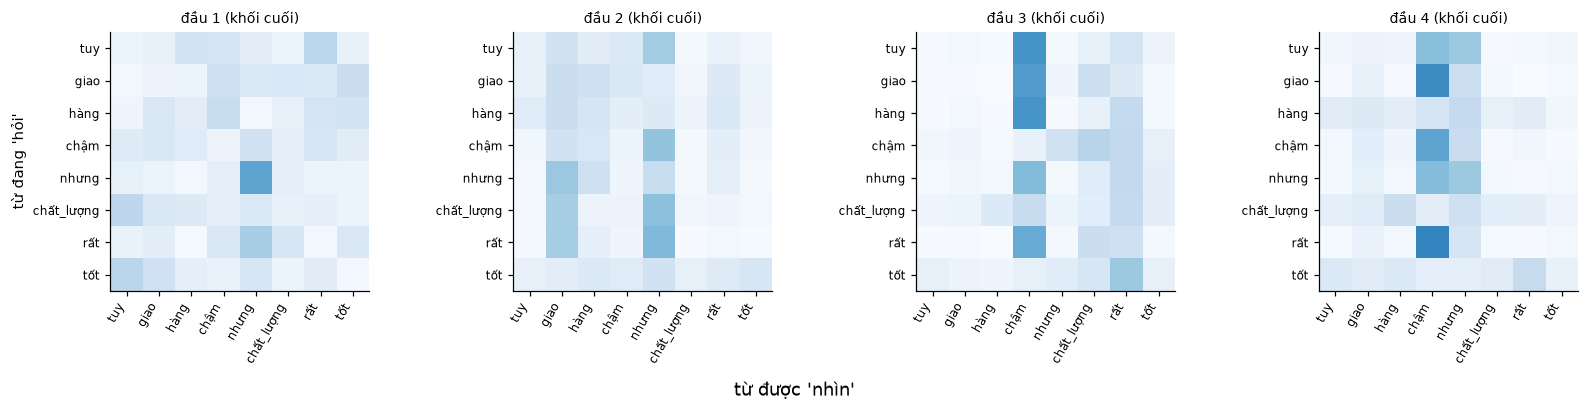

In [10]:
cau = "tuy giao hàng chậm nhưng chất lượng rất tốt"
toks = tach_tu(cau)
x = torch.tensor([[stoi.get(w, 1) for w in toks]])
tf_model.eval()
with torch.no_grad():
    logits, attn = tf_model(x, return_attn=True)
print("Từ:", toks)
xs = [round(float(v), 2) for v in logits.softmax(-1)[0]]
print("Dự đoán:", CLASSES[int(logits.argmax())], "| xác suất:", dict(zip(CLASSES, xs)))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for hd in range(4):
    axes[hd].imshow(attn[-1][0, hd].numpy(), cmap="Blues", vmin=0, vmax=1)
    axes[hd].set_xticks(range(len(toks))); axes[hd].set_xticklabels(toks, rotation=60, ha="right", fontsize=8)
    axes[hd].set_yticks(range(len(toks))); axes[hd].set_yticklabels(toks, fontsize=8)
    axes[hd].set_title(f"đầu {hd + 1} (khối cuối)", fontsize=9)
axes[0].set_ylabel("từ đang 'hỏi'"); fig.supxlabel("từ được 'nhìn'")
plt.tight_layout(); plt.show()

Lưu ý trước hết: mô hình dự đoán câu này là *tiêu cực*, trong khi đúng ra là *tích cực* (vế sau "nhưng" quyết định) — chính là điểm yếu trên câu khó mà ta đã thấy ở các bài trước. Giờ hãy quan sát từng đầu: một số đầu gần như chỉ nhìn chính nó (đường chéo), số khác trải đều, có thể có đầu tập trung vào một vài từ. **Cẩn thận khi diễn giải**: trọng số attention cho thấy *mô hình nhìn vào đâu* chứ không chứng minh *vì sao nó quyết định như vậy*. Với mô hình nhỏ huấn luyện từ đầu, các mẫu thường khá nhiễu.

## 7. Attention gỡ nút thắt của seq2seq

Quay lại bài toán **đảo ngược chuỗi chữ số** ở Bài 7: GRU không attention chỉ đạt ≈94% ở độ dài 8, ≈39% ở độ dài 12 và gần 0 từ độ dài 16. Giờ cho decoder **attention** lên mọi trạng thái encoder. Ta thử hai biến thể:

- **(A) attention chỉ dùng trạng thái GRU** để làm key/query.
- **(B) attention + chỉ số vị trí**: cộng embedding vị trí *tính từ cuối* câu nguồn vào key, và embedding bước giải mã vào query. Với đảo ngược, bước giải mã *i* cần nhìn đúng ô *thứ i tính từ cuối* — đó là thiết kế tay cho bài toán này, nhằm minh họa vai trò của thông tin vị trí.

Ta huấn luyện lại cả mô hình **(C) không attention** (cùng kiến trúc như Bài 7) để so sánh công bằng: cùng dữ liệu, cùng 3.000 bước, cùng seed.

In [11]:
VOC, BOS, MAXL = 10, 10, 32

def lay_batch(B, L, g):
    x = torch.randint(0, 10, (B, L), generator=g)
    y = x.flip(1)
    y_in = torch.cat([torch.full((B, 1), BOS), y[:, :-1]], 1)
    return x, y, y_in

class Seq2SeqAttn(nn.Module):
    def __init__(self, d=64, h=128, use_attn=True, use_pos=False):
        super().__init__()
        self.use_attn, self.use_pos = use_attn, use_pos
        self.out0 = nn.Linear(h, VOC)               # đầu ra khi KHÔNG dùng attention
        self.emb = nn.Embedding(VOC + 1, d)
        self.pos_src = nn.Embedding(MAXL, h)       # chỉ số tính TỪ CUỐI câu nguồn
        self.pos_tgt = nn.Embedding(MAXL, h)       # bước giải mã
        self.enc = nn.GRU(d, h, batch_first=True)
        self.dec = nn.GRU(d, h, batch_first=True)
        self.q = nn.Linear(h, h, bias=False)
        self.k = nn.Linear(h, h, bias=False)
        self.out = nn.Linear(2 * h, VOC)

    def encode(self, x):
        E, h = self.enc(self.emb(x))
        if self.use_pos:
            E = E + self.pos_src(torch.arange(x.size(1) - 1, -1, -1))[None]
        return E, h

    def attend(self, o, E, t0=0):
        if not self.use_attn:
            return self.out0(o), None
        q = o + (self.pos_tgt(torch.arange(t0, t0 + o.size(1)))[None] if self.use_pos else 0)
        w = (self.q(q) @ self.k(E).transpose(1, 2) / math.sqrt(E.size(-1))).softmax(-1)      # (B, T, L)
        return self.out(torch.cat([o, w @ E], -1)), w

    def forward(self, x, y_in):
        E, h = self.encode(x)
        o, _ = self.dec(self.emb(y_in), h)
        return self.attend(o, E)[0]

    @torch.no_grad()
    def decode(self, x):
        E, h = self.encode(x)
        y = torch.full((x.size(0), 1), BOS)
        outs, ws = [], []
        for t in range(x.size(1)):
            o, h = self.dec(self.emb(y), h)
            lg, w = self.attend(o, E, t0=t)
            y = lg[:, -1].argmax(-1, keepdim=True)
            outs.append(y)
            if w is not None:
                ws.append(w[:, -1])
        return torch.cat(outs, 1), (torch.stack(ws, 1) if ws else None)

def huan_luyen_s2s(model, steps=3000, seed=0):
    set_seed(seed)
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    for _ in range(steps):
        L = int(torch.randint(3, 17, (1,), generator=g))
        x, y, y_in = lay_batch(64, L, g)
        loss = F.cross_entropy(model(x, y_in).reshape(-1, VOC), y.reshape(-1))
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    return loss.item()

def acc_theo_do_dai(model, lengths=(4, 8, 12, 16, 20, 24), n=500, seed=123):
    g = torch.Generator().manual_seed(seed)
    model.eval(); res = {}
    for L in lengths:
        x, y, _ = lay_batch(n, L, g)
        res[L] = round((model.decode(x)[0] == y).all(1).float().mean().item(), 3)
    return res

ket_qua = {}
models = {}
cau_hinh = [("(C) GRU không attention (như Bài 7)", dict(use_attn=False)),
            ("(A) attention, không chỉ số vị trí", dict(use_attn=True, use_pos=False)),
            ("(B) attention + vị trí từ cuối", dict(use_attn=True, use_pos=True))]
for ten, kw in cau_hinh:
    t0 = time.time()
    set_seed(0)
    m = Seq2SeqAttn(**kw)
    huan_luyen_s2s(m)
    models[ten] = m
    ket_qua[ten] = acc_theo_do_dai(m)
    print(f"{ten}: xong trong {time.time() - t0:.0f}s")

bang = pd.DataFrame(ket_qua).T
bang.columns = [f"L={c}" for c in bang.columns]
bang

(C) GRU không attention (như Bài 7): xong trong 122s


(A) attention, không chỉ số vị trí: xong trong 165s


(B) attention + vị trí từ cuối: xong trong 153s


,L=4,L=8,L=12,L=16,L=20,L=24
(C) GRU không attention (như Bài 7),1.0,0.950,0.494,0.026,0.0,0.00
"(A) attention, không chỉ số vị trí",1.0,0.988,0.958,0.818,0.5,0.09
(B) attention + vị trí từ cuối,1.0,1.000,1.000,1.000,0.0,0.00


Lưu ý các độ dài: huấn luyện chỉ thấy L ≤ 16; L = 20 và 24 là **ngoài phạm vi**.

**Đọc bảng:**

- **Attention là bước nhảy lớn.** Ở L=12, từ ≈49% (C) lên ≈96% (A) và 100% (B); ở L=16, từ ≈3% lên ≈82% (A) và 100% (B). Decoder không còn phải moi thông tin từ một vector nén mà *nhìn thẳng vào* ô cần thiết. (Số của (C) hơi khác Bài 7 vì khởi tạo ngẫu nhiên khác dù cùng kiến trúc — nhắc ta rằng một lần chạy chỉ là một mẫu.)
- **Thông tin vị trí giúp ở trong phạm vi huấn luyện** (B > A).
- **Nhưng B sụp đổ ngoài phạm vi (L=20, 24 → 0%)** vì embedding vị trí *học được* cho các chỉ số 17+ chưa từng được huấn luyện: nó không **ngoại suy**. Biến thể A tuy kém hơn ở L≤16 lại còn giữ được ≈50% ở L=20 (và ≈9% ở L=24). Đây là lý do nghiên cứu tiếp tục tìm cách mã hóa vị trí tốt hơn (tương đối, RoPE, ALiBi) và là nguyên nhân LLM có "độ dài ngữ cảnh" giới hạn.

nguồn : [1, 4, 7, 5, 6, 0, 2, 3, 8, 4]
đảo   : [4, 8, 3, 2, 0, 6, 5, 7, 4, 1] | đúng: True


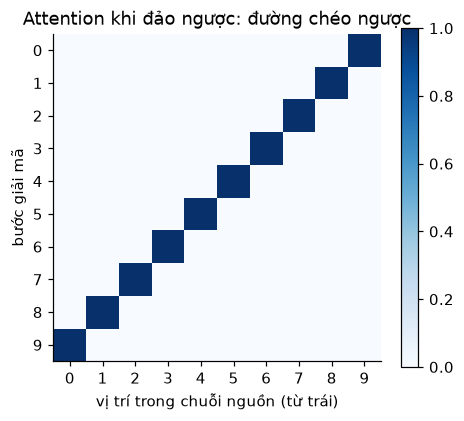

In [12]:
mB = models["(B) attention + vị trí từ cuối"]
g = torch.Generator().manual_seed(5)
x, y, _ = lay_batch(1, 10, g)
pred, W = mB.decode(x)
print("nguồn :", x[0].tolist()); print("đảo   :", pred[0].tolist(), "| đúng:", bool((pred == y).all()))

plt.figure(figsize=(4.8, 4))
plt.imshow(W[0].numpy(), cmap="Blues", vmin=0, vmax=1)
plt.xlabel("vị trí trong chuỗi nguồn (từ trái)"); plt.ylabel("bước giải mã")
plt.title("Attention khi đảo ngược: đường chéo ngược")
plt.xticks(range(10)); plt.yticks(range(10)); plt.colorbar(); plt.show()

Đồ thị là **đường chéo ngược**: ở bước giải mã *i*, mô hình dồn gần hết trọng số vào ô nguồn thứ (L−1−i). Mô hình đã *tự học* căn chỉnh nguồn–đích — đúng điều ta mong và là điểm khởi đầu của dịch máy neural hiện đại.

## 8. Mini-GPT: sinh văn bản là dự đoán token kế tiếp

Bây giờ ta bỏ encoder, chỉ giữ chồng khối Transformer với **mặt nạ nhân quả**, huấn luyện để đoán token kế tiếp — đúng cách GPT, Qwen và các LLM được huấn luyện (chỉ khác quy mô: hàng tỉ tham số, hàng nghìn tỉ token).

từ điển: 458 | token train: 13185 | token valid: 3009
Số tham số: 381,984 | token train: 13185


159s | perplexity valid tốt nhất = 8.1 tại bước 600


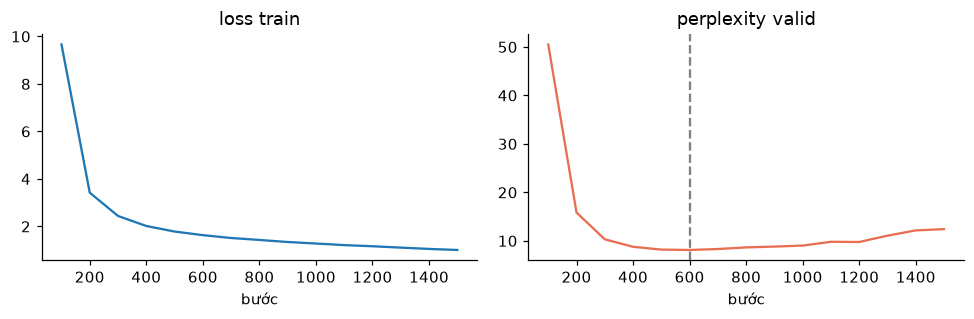

In [13]:
def cau_thanh_tu(text):
    out = []
    for cau in split_sentences(normalize(text, emoji="drop")):
        toks = [w for w in segment(cau).split() if any(ch.isalnum() for ch in w)]
        if toks:
            out.append(toks)
    return out

cau_tr = [s for t in train["text"] for s in cau_thanh_tu(t)]
cau_va = [s for t in valid["text"] for s in cau_thanh_tu(t)]
from collections import Counter
dem = Counter(w for s in cau_tr for w in s)
itos_lm = ["<eos>", "<unk>"] + sorted(w for w, c in dem.items() if c >= 2)
stoi_lm = {w: i for i, w in enumerate(itos_lm)}

def dong_token(sents):
    ids = []
    for s in sents:
        ids += [stoi_lm.get(w, 1) for w in s] + [0]            # <eos> ngăn cách các câu
    return torch.tensor(ids)

tr_ids, va_ids = dong_token(cau_tr), dong_token(cau_va)
print("từ điển:", len(itos_lm), "| token train:", len(tr_ids), "| token valid:", len(va_ids))

class MiniGPT(nn.Module):
    def __init__(self, V, d=96, h=4, n_layers=3, ctx=24, p=0.1):
        super().__init__()
        self.ctx = ctx
        self.emb = nn.Embedding(V, d)
        self.pos = nn.Embedding(ctx, d)
        self.blocks = nn.ModuleList([Block(d, h, p) for _ in range(n_layers)])
        self.ln = nn.LayerNorm(d)
        self.head = nn.Linear(d, V, bias=False)
        self.head.weight = self.emb.weight                    # chia sẻ trọng số vào/ra (weight tying)

    def forward(self, x):
        L = x.size(1)
        mask = torch.tril(torch.ones(L, L, dtype=torch.bool))[None, None]
        z = self.emb(x) + self.pos(torch.arange(L))
        for b in self.blocks:
            z, _ = b(z, mask)
        return self.head(self.ln(z))

def lay_cua_so(ids, B, ctx, g):
    i = torch.randint(0, len(ids) - ctx - 1, (B,), generator=g)
    x = torch.stack([ids[j:j + ctx] for j in i]); y = torch.stack([ids[j + 1:j + ctx + 1] for j in i])
    return x, y

@torch.no_grad()
def perplexity_lm(model, ids, ctx=24):
    model.eval(); tot, n = 0.0, 0
    for s in range(0, len(ids) - ctx - 1, ctx):
        x, y = ids[s:s + ctx][None], ids[s + 1:s + ctx + 1][None]
        tot += F.cross_entropy(model(x)[0], y[0], reduction="sum").item(); n += ctx
    return math.exp(tot / n)

import copy
set_seed(0)
gpt = MiniGPT(len(itos_lm))
opt = torch.optim.AdamW(gpt.parameters(), lr=2e-3, weight_decay=0.01)
g = torch.Generator().manual_seed(0)
print("Số tham số:", f"{sum(p.numel() for p in gpt.parameters()):,}", "| token train:", len(tr_ids))

t0 = time.time()
nhat_ky, tot_nhat, state_tot, loss_tr = [], 1e9, None, []
for step in range(1, 1501):
    gpt.train()
    x, y = lay_cua_so(tr_ids, 32, gpt.ctx, g)
    loss = F.cross_entropy(gpt(x).reshape(-1, len(itos_lm)), y.reshape(-1))
    opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(gpt.parameters(), 1.0); opt.step()
    loss_tr.append(loss.item())
    if step % 100 == 0:
        pp = perplexity_lm(gpt, va_ids)
        nhat_ky.append((step, float(np.mean(loss_tr[-100:])), pp))
        if pp < tot_nhat:
            tot_nhat, state_tot, buoc_tot = pp, copy.deepcopy(gpt.state_dict()), step
gpt.load_state_dict(state_tot)               # dừng sớm: giữ checkpoint có perplexity valid thấp nhất
print(f"{time.time() - t0:.0f}s | perplexity valid tốt nhất = {tot_nhat:.1f} tại bước {buoc_tot}")

nk = pd.DataFrame(nhat_ky, columns=["bước", "loss train (TB 100 bước)", "perplexity valid"])
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(nk["bước"], nk["loss train (TB 100 bước)"]); ax[0].set_title("loss train"); ax[0].set_xlabel("bước")
ax[1].plot(nk["bước"], nk["perplexity valid"], color="#e76f51"); ax[1].axvline(buoc_tot, ls="--", color="gray")
ax[1].set_title("perplexity valid"); ax[1].set_xlabel("bước")
plt.tight_layout(); plt.show()

**Quá khớp xuất hiện rất sớm.** Loss train cứ giảm, nhưng perplexity valid chạm đáy ở khoảng bước 500–600 rồi *tăng lên*. Mô hình có ~380 nghìn tham số mà chỉ có ~12 nghìn token để học — nó bắt đầu *thuộc lòng* kho huấn luyện. Ta dùng đúng thủ thuật ở Bài 6: **dừng sớm** và giữ checkpoint tốt nhất. (Ở quy mô lớn, các LLM giải quyết bằng cách có *rất nhiều* dữ liệu, không lặp lại quá nhiều epoch.)

Chú ý: đây là perplexity trên *cửa sổ 24 token cắt ngang các câu* (có `<eos>`), nên **không** so trực tiếp với số ở Bài 4 (từ điển, cách đệm và tập câu khác nhau); chỉ cần biết hai số cùng cỡ (≈8: mini-GPT ≈8,1; trigram nội suy ≈8,7).

Giờ cho mô hình **sinh văn bản**. Hai tham số điều khiển độ ngẫu nhiên: `temperature` (làm phẳng/nhọn phân phối) và **top-k** (chỉ lấy mẫu trong k từ khả dĩ nhất).

In [14]:
@torch.no_grad()
def sinh(model, bat_dau=(), T=0.8, top_k=10, toi_da=22, seed=0):
    gen = torch.Generator().manual_seed(seed)
    ids = [0] + [stoi_lm[w] for w in bat_dau if w in stoi_lm]           # bắt đầu bằng <eos>
    model.eval()
    for _ in range(toi_da):
        x = torch.tensor(ids[-model.ctx:])[None]
        logits = model(x)[0, -1] / T
        if top_k:
            kth = logits.topk(top_k).values[-1]
            logits = logits.masked_fill(logits < kth, float("-inf"))
        nxt = int(torch.multinomial(logits.softmax(-1), 1, generator=gen))
        if nxt == 0:
            break
        ids.append(nxt)
    return " ".join(itos_lm[i] for i in ids[1:]).replace("_", " ")

print("--- sinh từ đầu câu (T=0,8; top-k=10) ---")
for sd in range(5):
    print("  •", sinh(gpt, seed=sd))
print("--- bắt đầu bằng 'giao hàng' / 'tuy' ---")
for pre in [("giao", "hàng"), ("tuy",), ("không",)]:
    print(f"  • [{' '.join(pre)}] →", sinh(gpt, pre, seed=3))

--- sinh từ đầu câu (T=0,8; top-k=10) ---
  • mình dùng bản mới nhất
  • mình dùng bản mới nhất
  • giao diện thực sự thoáng
  • sẽ ủng hộ tiếp
  • tốc độ giảng rất hợp lý
--- bắt đầu bằng 'giao hàng' / 'tuy' ---
  • [giao hàng] → giao hàng hơi chậm và tư vấn của shop rất chu đáo
  • [tuy] → tuy phục vụ khá chậm
  • [không] → không khuyên mua


Các câu sinh ra **gọn và đúng ngữ pháp** ("giao hàng hơi chậm và tư vấn của shop rất chu đáo") nhưng **lặp lại nhiều** ("mình dùng bản mới nhất" xuất hiện hai lần trong năm mẫu): mô hình chỉ thấy ~13 nghìn token của một kho tổng hợp nên về cơ bản đã *thuộc* các khuôn câu và tái tổ hợp chúng, không sáng tạo. Cửa sổ của nó là 24 token chứ không chỉ 2 từ như trigram và perplexity thấp hơn một chút (≈ 8,1 so với ≈ 8,7), nhưng chỉ với vài mẫu ta *không* nên kết luận câu "mượt" hơn n-gram ở Bài 4 — hãy đặt hai bộ mẫu cạnh nhau và tự đánh giá.

## 9. Tổng kết

| Khái niệm | Điều cần nhớ |
|---|---|
| Attention | tra cứu mềm: softmax(QKᵀ/√d)·V; decoder nhìn mọi trạng thái encoder |
| Chia √d | giữ softmax khỏi bão hòa khi d lớn |
| Mặt nạ | padding (bỏ ô đệm) và nhân quả (không nhìn tương lai) |
| Mã hóa vị trí | self-attention không biết thứ tự; vị trí học được không ngoại suy |
| Multi-head | nhiều "góc nhìn" song song |
| Khối Transformer | attention + FFN + residual + LayerNorm |
| Độ phức tạp | attention tốn $O(L^2)$ bộ nhớ/tính toán theo độ dài L → giới hạn độ dài ngữ cảnh |
| GPT / LLM | Transformer nhân quả dự đoán token kế tiếp, ở quy mô rất lớn |

## Bài tập

1. **(Dễ)** Đổi số đầu `h` từ 4 sang 1 và 8 trong `TransformerPhanLoai`. Kết quả thay đổi thế nào? Số tham số có đổi không? (gợi ý: `d = h × dk`)
2. **(Dễ)** Cho mini-GPT sinh với `T` ∈ {0.3, 1.0, 1.5} và `top_k` ∈ {None, 3, 50}. Mô tả ảnh hưởng của từng tham số.
3. **(Vừa)** Bỏ mã hóa vị trí khỏi `TransformerPhanLoai`. Macro-F1 trên valid/câu khó thay đổi bao nhiêu? Vì sao với phân loại cảm xúc ảnh hưởng nhỏ hơn bạn nghĩ?
4. **(Vừa)** Đo thời gian và bộ nhớ của `MultiHeadAttention` khi L = 64, 256, 1024. Xác nhận độ tăng $O(L^2)$.
5. **(Khó)** Cài **cross-attention** vào `Block` để tạo decoder Transformer đầy đủ; huấn luyện lại bài toán đảo chuỗi với chỉ attention (không GRU) và xem nó có ngoại suy tốt hơn không khi dùng mã hóa vị trí hình sin thay vì học được.

<details>
<summary><b>Gợi ý đáp án</b></summary>

1. Số tham số **không đổi** (qkv và o đều d×d); chỉ đổi cách chia chiều. 1 đầu có "một góc nhìn", 8 đầu mỗi đầu chỉ 8 chiều. Với d nhỏ, quá nhiều đầu có thể hại.
2. T nhỏ → câu an toàn, lặp; T lớn → đa dạng nhưng dễ lạc. Top-k nhỏ cắt đuôi phân phối (ít nhiễu); `None` cho phép từ rất hiếm.
3. Phân loại bằng gộp trung bình phần lớn dựa vào *tập từ*; vị trí đóng góp ít. Với phủ định/"nhưng" thì có ảnh hưởng nhẹ.
4. Thời gian/bộ nhớ ~ L² (ma trận `L×L` mỗi đầu): 4× L → 16× chi phí.
5. Cross-attention: Q từ decoder, K/V từ encoder. Hàm sin/cos thường ngoại suy hơi tốt hơn embedding học được nhưng không hoàn toàn.
</details>

**Tiếp theo → Bài 9:** dùng thư viện 🤗 Transformers, tokenizer subword và mô hình tiền huấn luyện.

**Đọc thêm:** Vaswani và cộng sự, *Attention Is All You Need* (2017) · [The Annotated Transformer](https://nlp.seas.harvard.edu/annotated-transformer/) · [Hugging Face NLP Course, Chương 1 (tiếng Việt): Cơ chế hoạt động của Transformer](https://huggingface.co/docs/course/vi/chapter1/4)